# Notebook description

Despite the improvements obtained through higher image resolution and data augmentation, certain absence-related classes continued to exhibit limited detection performance.

To further investigate these limitations, an alternative problem formulation was introduced. Instead of explicitly detecting both PPE presence and absence, this approach focuses exclusively on detecting the presence of protective equipment.

The model retains the 960-pixel input resolution and data augmentation strategy, allowing the exploration of whether simplifying the class structure can improve detection performance.

# Dataset import

Imports and versions

In [1]:
!pip install -q ultralytics

import ultralytics
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ultralytics.data.utils import check_det_dataset
import os
import yaml
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from PIL import Image
from collections import Counter


print("Ultralytics version:", ultralytics.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics version: 8.4.212
NumPy version: 2.4.6
Pandas version: 2.2.3


Chack data and create paths

In [2]:
data = check_det_dataset("construction-ppe.yaml")
print("Dataset downloaded and verified")

dataset_path = Path(data["path"])
print("Dataset path:", dataset_path)

print("Number of classes:", data["nc"])
print("Class names:", data["names"])

train_img_path = Path(data["train"])
print("Training images:", train_img_path)

val_img_path = Path(data["val"])
print("Validation images:", val_img_path)


WARNING ⚠️ Dataset 'construction-ppe.yaml' images not found, missing path '/content/datasets/construction-ppe/images/val'
Unzipping /content/datasets/construction-ppe.zip to /content/datasets/construction-ppe...: 100% ━━━━━━━━━━━━ 2004/2004 231.9files/s 8.6s
Dataset download success ✅ (14.8s), saved to /content/datasets

Dataset downloaded and verified
Dataset path: /content/datasets/construction-ppe
Number of classes: 12
Class names: {0: 'helmet', 1: 'gloves', 2: 'vest', 3: 'boots', 4: 'goggles', 5: 'Person', 6: 'no_helmet', 7: 'no_goggle', 8: 'no_gloves', 9: 'no_boots', 10: 'forklift', 11: 'no_vest'}
Training images: /content/datasets/construction-ppe/images/train
Validation images: /content/datasets/construction-ppe/images/val


# Data augmentation

In [3]:
!pip install -q -U albumentations pyyaml opencv-python-headless

import albumentations as A
import cv2
import numpy as np
import os
import shutil
import yaml

from pathlib import Path
from tqdm.notebook import tqdm


transform = A.Compose([
    A.RandomBrightnessContrast(
        brightness_limit=0.2,
        contrast_limit=0.2,
        p=0.7
    ),

    A.RandomGamma(
        gamma_limit=(80, 120),
        p=0.3
    ),

    A.CLAHE(
        clip_limit=2.0,
        p=0.2
    ),

    A.RandomShadow(
        p=0.3
    ),

    A.HueSaturationValue(
        hue_shift_limit=5,
        sat_shift_limit=15,
        val_shift_limit=10,
        p=0.3
    ),

    A.GaussNoise(
        p=0.2
    ),

    A.GaussianBlur(
        blur_limit=(3, 5),
        p=0.15
    ),

], bbox_params=A.BboxParams(
    format="yolo",
    label_fields=["class_labels"]
))

/usr/local/lib/python3.13/dist-packages/albumentations/core/composition.py:331: UserWarning: Got processor for bboxes, but no transform to process it.
  self._set_keys()


In [4]:
dataset_path = Path(
    "/content/datasets/construction-ppe"
)

output_path = Path(
    "/content/datasets/construction-ppe-augmented"
)

num_augmentations = 2

In [5]:
def load_yolo_labels(label_path):

    boxes = []
    class_labels = []

    if not label_path.exists():
        return boxes, class_labels

    with open(label_path, "r") as f:

        for line in f:
            values = line.strip().split()

            if len(values) != 5:
                continue

            class_id = int(values[0])

            bbox = list(map(float, values[1:]))

            boxes.append(bbox)
            class_labels.append(class_id)

    return boxes, class_labels

In [6]:
def save_yolo_labels(label_path, boxes, class_labels):

    with open(label_path, "w") as f:

        for bbox, class_id in zip(boxes, class_labels):

            values = [class_id] + list(bbox)

            f.write(
                " ".join(map(str, values)) + "\n"
            )

In [7]:
def clip_yolo_bbox(bbox):

    x, y, w, h = bbox

    x_min = max(0.0, x - w / 2)
    y_min = max(0.0, y - h / 2)

    x_max = min(1.0, x + w / 2)
    y_max = min(1.0, y + h / 2)

    new_x = (x_min + x_max) / 2
    new_y = (y_min + y_max) / 2

    new_w = x_max - x_min
    new_h = y_max - y_min

    return [new_x, new_y, new_w, new_h]

In [8]:
for folder in [
    "images/train",
    "labels/train",
    "images/val",
    "labels/val"
]:
    (output_path / folder).mkdir(
        parents=True,
        exist_ok=True
    )


shutil.copytree(
    dataset_path / "images/val",
    output_path / "images/val",
    dirs_exist_ok=True
)

shutil.copytree(
    dataset_path / "labels/val",
    output_path / "labels/val",
    dirs_exist_ok=True
)

image_dir = dataset_path / "images/train"
label_dir = dataset_path / "labels/train"

output_images = output_path / "images/train"
output_labels = output_path / "labels/train"

image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}

image_files = [
    p for p in image_dir.iterdir()
    if p.suffix.lower() in image_extensions
]


for image_path in tqdm(image_files):

    image = cv2.imread(str(image_path))

    if image is None:
        continue

    image = cv2.cvtColor(
        image, cv2.COLOR_BGR2RGB
    )

    label_path = label_dir / f"{image_path.stem}.txt"

    boxes, class_labels = load_yolo_labels(label_path)

    boxes = [
      clip_yolo_bbox(bbox)
      for bbox in boxes
    ]

    shutil.copy2(
        image_path,
        output_images / image_path.name
    )

    if label_path.exists():
        shutil.copy2(
            label_path,
            output_labels / label_path.name
        )

    for i in range(num_augmentations):

        augmented = transform(
            image=image,
            bboxes=boxes,
            class_labels=class_labels
        )

        aug_image = cv2.cvtColor(
            augmented["image"],
            cv2.COLOR_RGB2BGR
        )

        aug_boxes = augmented["bboxes"]
        aug_classes = augmented["class_labels"]

        new_name = f"{image_path.stem}_aug{i+1}"

        cv2.imwrite(
            str(output_images / f"{new_name}{image_path.suffix}"),
            aug_image
        )


        save_yolo_labels(
            output_labels / f"{new_name}.txt",
            aug_boxes,
            aug_classes
        )

print("Data augmentation completed")

  0%|          | 0/800 [00:00<?, ?it/s]

Data augmentation completed


New class distribution

In [9]:
print("Output path:", output_path)
print("Train labels:", (output_path / "labels/train").exists())
print("Val labels:", (output_path / "labels/val").exists())

print("Train files:", len(list((output_path / "labels/train").glob("*.txt"))))
print("Val files:", len(list((output_path / "labels/val").glob("*.txt"))))

Output path: /content/datasets/construction-ppe-augmented
Train labels: True
Val labels: True
Train files: 2400
Val files: 200


In [10]:
from collections import Counter

class_names = {
    0: 'helmet',
    1: 'gloves',
    2: 'vest',
    3: 'boots',
    4: 'goggles',
    5: 'Person',
    6: 'no_helmet',
    7: 'no_goggle',
    8: 'no_gloves',
    9: 'no_boots',
    10: 'forklift',
    11: 'no_vest'
}


def count_instances(split):

    labels_dir = output_path / "labels" / split

    counts = Counter()

    for file in labels_dir.glob("*.txt"):

        with open(file, "r") as f:

            for line in f:

                values = line.strip().split()

                if values:
                    class_id = int(float(values[0]))
                    counts[class_id] += 1

    return counts


train_counts = count_instances("train")
val_counts = count_instances("val")

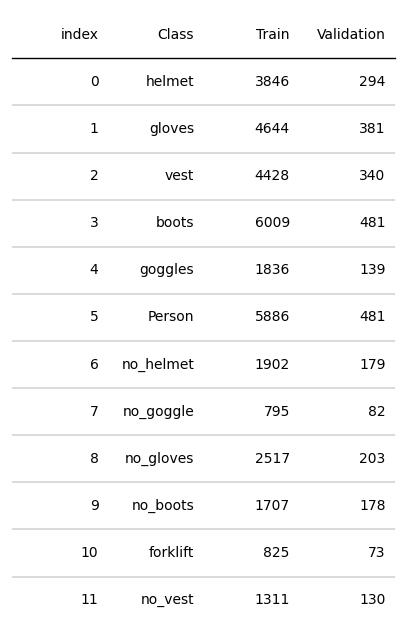

In [11]:
!pip install plottable

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from plottable import Table

df = pd.DataFrame({
    "Class": list(class_names.values()),
    "Train": [train_counts[i] for i in class_names],
    "Validation": [val_counts[i] for i in class_names]
})

fig, ax = plt.subplots(figsize=(5, 8))
tab = Table(df)

plt.show()

In [12]:

with open(dataset_path / "data.yaml", "r") as f:
    data = yaml.safe_load(f)


data["path"] = str(output_path)
data["train"] = "images/train"
data["val"] = "images/val"


with open(output_path / "data.yaml", "w") as f:
    yaml.safe_dump(data, f, sort_keys=False)

print(data)

{'path': '/content/datasets/construction-ppe-augmented', 'train': 'images/train', 'val': 'images/val', 'names': {0: 'helmet', 1: 'gloves', 2: 'vest', 3: 'boots', 4: 'goggles', 5: 'Person', 6: 'no_helmet', 7: 'no_goggle', 8: 'no_gloves', 9: 'no_boots', 10: 'forklift', 11: 'no_vest'}}


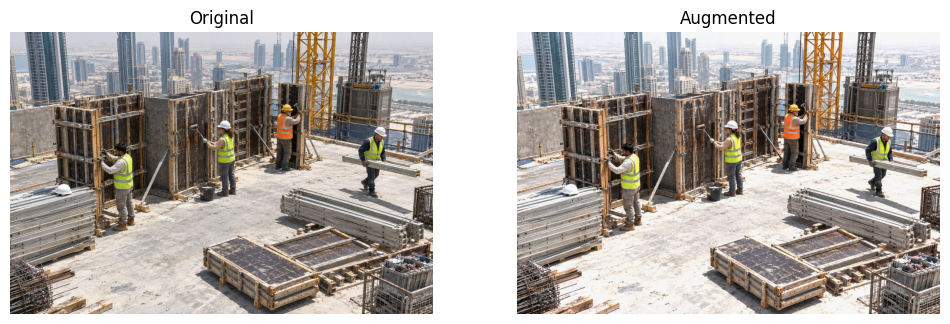

In [13]:
import matplotlib.pyplot as plt

original = cv2.imread(
    str(output_images / image_files[100].name)
)

augmented = cv2.imread(
    str(output_images /
        f"{image_files[100].stem}_aug1{image_files[100].suffix}")
)

original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)
augmented = cv2.cvtColor(augmented, cv2.COLOR_BGR2RGB)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].imshow(original)
ax[0].set_title("Original")

ax[1].imshow(augmented)
ax[1].set_title("Augmented")

for a in ax:
    a.axis("off")

plt.show()

# Fine-tuning YOLO

## Model with data augmented and less classes

### Training

In [14]:
from ultralytics import YOLO

model2 = YOLO("yolo26n.pt")

yaml = str(output_path / "data.yaml")

results = model2.train(
    data=yaml,
    epochs=50,
    patience=20,
    imgsz=960,
    batch=16,
    device=0,
    classes=[0, 1, 2, 3, 4, 5, 10]
)

Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=[0, 1, 2, 3, 4, 5, 10], close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datasets/construction-ppe-augmented/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, 

#### Evaluate and save weights

### Results

#### Plotted metrics

Mounted at /content/drive


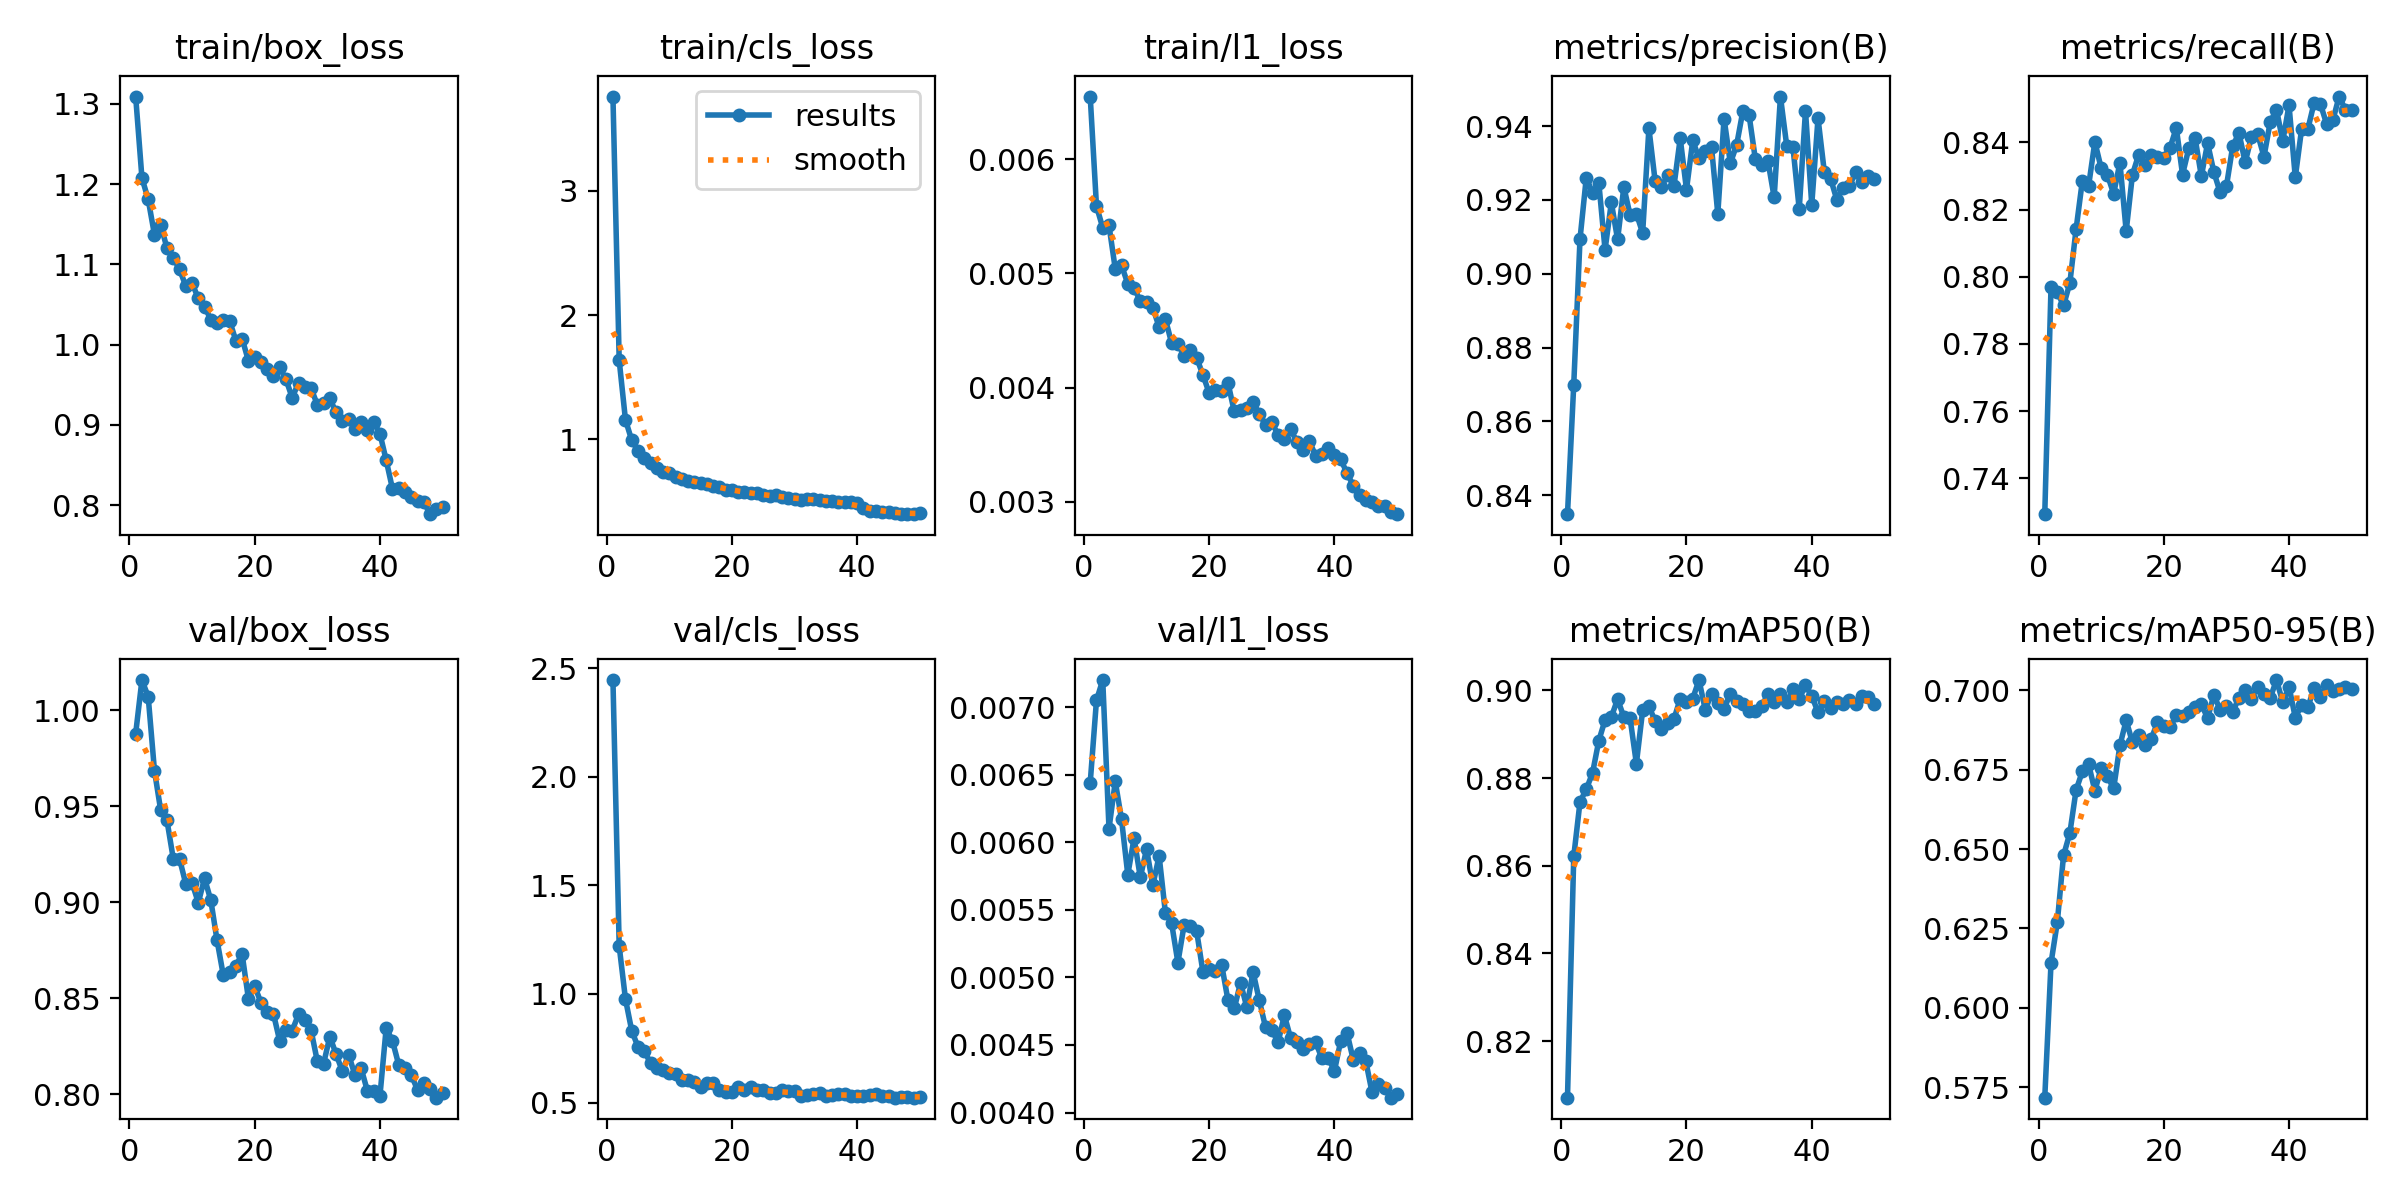

In [16]:
from ultralytics import YOLO
from ultralytics.utils.plotting import plot_results
from google.colab import drive
from IPython.display import Image, display
import os
import shutil

drive.mount('/content/drive')

save_dir = results.save_dir

plot_results(file=os.path.join(save_dir, "results.csv"))

display(Image(filename=os.path.join(save_dir, "results.png")))


Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,392,408 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3394.5±510.3 MB/s, size: 830.4 KB)
val: Scanning /content/datasets/construction-ppe-augmented/labels/val.cache... 200 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 200/200 44.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 2.2it/s 6.0s
                   all        200       2961       0.54       0.49      0.524      0.411
                helmet        146        294      0.953      0.847       0.91      0.733
                gloves        136        381      0.936      0.768       0.86      0.683
                  vest        157        340      0.971      0.909      0.937      0.764
                 boots        155        481      0.863      0.703      0.832       0.64
               gog

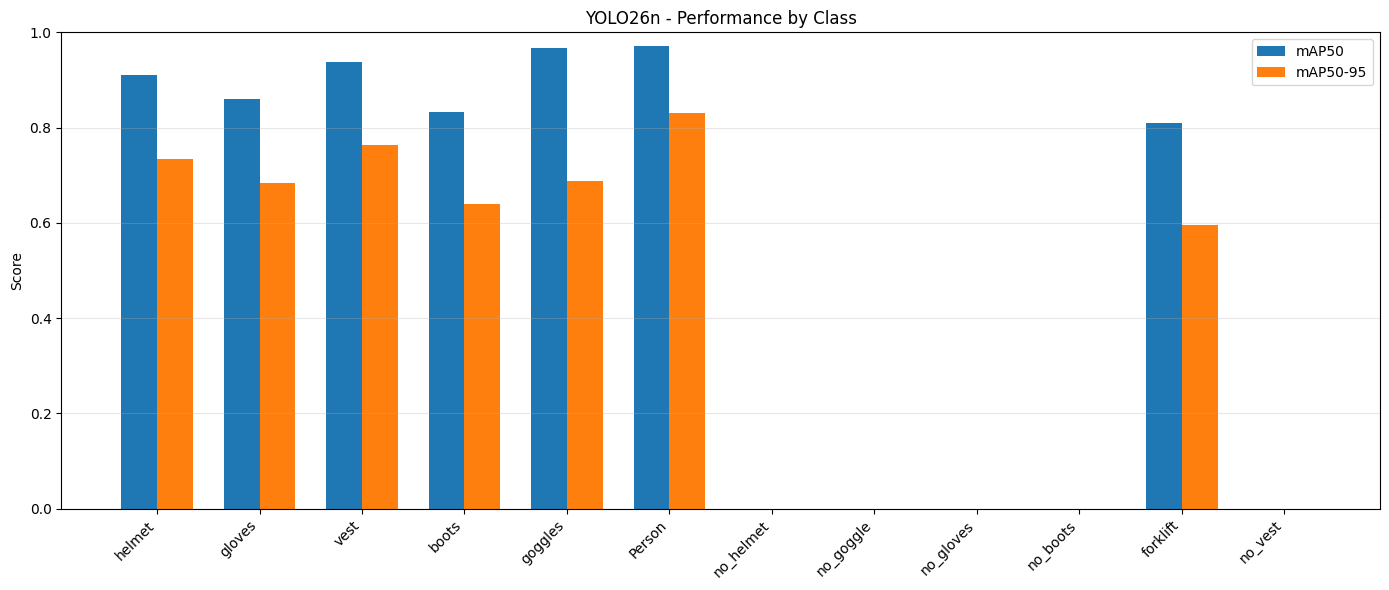

In [17]:
import matplotlib.pyplot as plt
import numpy as np

modelweights = YOLO(
    os.path.join(save_dir, "weights", "best.pt")
)

metrics = modelweights.val(
    data=yaml,
    imgsz=960
)

names = metrics.names
class_ids = metrics.box.ap_class_index

class_names = [names[int(i)] for i in class_ids]

map50 = metrics.box.ap50
map5095 = metrics.box.maps

x = np.arange(len(class_names))
width = 0.35

plt.figure(figsize=(14, 6))

plt.bar(x - width/2, map50, width, label="mAP50")
plt.bar(x + width/2, map5095, width, label="mAP50-95")

plt.xticks(x, class_names, rotation=45, ha="right")
plt.ylabel("Score")
plt.title("YOLO26n - Performance by Class")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

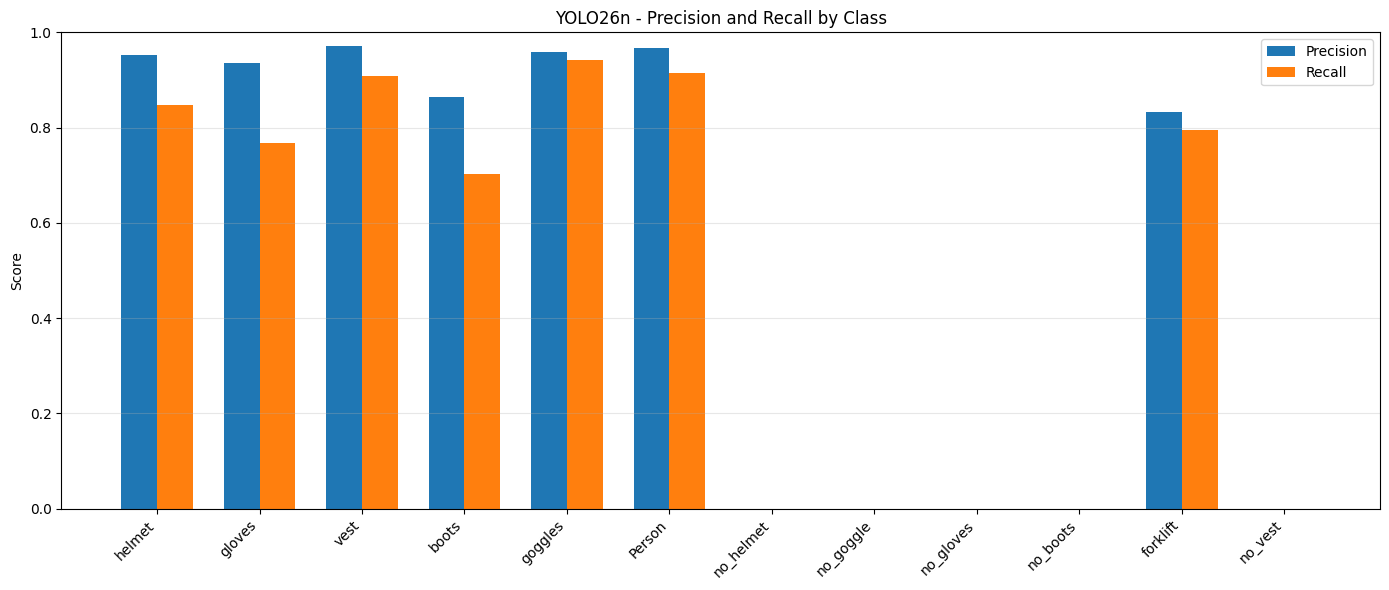

In [18]:
precision = metrics.box.p
recall = metrics.box.r

x = np.arange(len(class_names))
width = 0.35

plt.figure(figsize=(14, 6))

plt.bar(x - width/2, precision, width, label="Precision")
plt.bar(x + width/2, recall, width, label="Recall")

plt.xticks(x, class_names, rotation=45, ha="right")
plt.ylabel("Score")
plt.title("YOLO26n - Precision and Recall by Class")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

#### Visualize predictions

In [20]:
import glob

label_images = glob.glob(
    os.path.join(metrics.save_dir, "val_batch*_labels.jpg")
)

pred_images = glob.glob(
    os.path.join(metrics.save_dir, "val_batch*_pred.jpg")
)

for label, pred in zip(sorted(label_images), sorted(pred_images)):

    print("Ground Truth")
    display(Image(filename=label))

    print("Predictions")
    display(Image(filename=pred))

Output hidden; open in https://colab.research.google.com to view.

#### Save weights

In [21]:
destination = "/content/drive/MyDrive/PPE_Construction_YOLO/weights"

os.makedirs(destination, exist_ok=True)

shutil.copy(
    os.path.join(save_dir, "weights", "best.pt"),
    os.path.join(destination, "model4.pt")
)

print("Saved files:", os.listdir(destination))

Saved files: ['last.pt', 'best.pt', 'model1.pt', 'model3.pt', 'model4.pt']


# Observations

The alternative problem formulation achieved the highest overall detection performance among the experiments conducted, reaching a mAP50 of 0.890 and a mAP50-95 of 0.701.

By focusing exclusively on PPE presence, the model achieved more consistent detection performance across the evaluated object categories. These results suggest that simplifying the class structure may help the model learn more discriminative visual representations for PPE detection.

However, this approach introduces an important limitation: detecting the presence of protective equipment does not necessarily establish whether individual workers are complying with safety requirements.

Therefore, further investigation would be necessary to associate detected PPE with individual workers and assess equipment compliance. This could be explored as a potential extension of the current project.